In [1]:
import pandas as pd
import glob
import pycountry
import numpy as np

In [2]:
df_to_check=pd.read_csv("../newdata/named_cleaned_data.csv")
df_to_check.loc[df_to_check["Country Name"].str.contains("Germany"), "Mehrals1000Deutsche_boolean"] = "true"
df_to_check[df_to_check["Country Name"].str.contains("Germany")]["Mehrals1000Deutsche_boolean"]

/var/folders/d_/6z_vk0mx7j10g1h2zrjh_6f00000gn/T/ipykernel_48369/968621439.py:2: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'true' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  df_to_check.loc[df_to_check["Country Name"].str.contains("Germany"), "Mehrals1000Deutsche_boolean"] = "true"


137    true
Name: Mehrals1000Deutsche_boolean, dtype: object

In [3]:
df_to_check=df_to_check.sort_values("Country Name").reset_index(drop=True)
df_to_check


,Country Name,Country Code,Land,BIP_rel_D,PurchasingPower_rel_D,Bevoelkerungsdichte,Freedom_Score,Sonnenstunde_pro_Tag,Zeitunterschied_D,HoechsterPunkt_m,...,LGBTQ,Mehrals5Morde_pro_100k_boolean,Mehrals1000Deutsche_boolean,Alkoholverbot_boolean,Kueste_boolean,Christian_boolean,Muslim_boolean,Jewish_boolean,English_boolean,Cuisine_boolean
0,Albania,ALB,Albanien,17.9,55.2,100.2,68.0,7.0,0.0,2764.0,...,62.3,False,False,False,True,True,True,False,True,True
1,Algeria,DZA,Algerien,10.1,41.6,19.4,31.0,8.9,1.0,2908.0,...,3.7,False,False,False,True,False,True,False,False,True
2,Angola,AGO,Angola,3.8,32.9,29.5,28.0,6.4,1.0,2620.0,...,48.6,False,False,False,True,True,True,False,False,False
3,Argentina,ARG,Argentinien,24.8,59.5,16.6,85.0,6.1,5.0,6961.0,...,89.4,False,True,False,True,True,False,False,True,True
4,Armenia,ARM,Armenien,15.2,48.3,105.1,54.0,6.8,2.0,4090.0,...,43.2,False,False,False,False,True,False,False,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
145,Uzbekistan,UZB,Usbekistan,5.7,34.5,80.9,12.0,7.3,3.0,4643.0,...,23.2,False,True,False,False,True,True,False,False,False
146,"Venezuela, RB",VEN,Venezuela,28.6,81.0,32.1,13.0,7.9,6.0,4978.0,...,50.0,True,True,False,True,True,False,False,True,True
147,Viet Nam,VNM,Vietnam,8.5,37.3,320.2,20.0,5.8,5.0,3147.0,...,52.3,False,False,False,True,True,False,False,False,True
148,Zambia,ZMB,Sambia,2.2,37.9,27.9,53.0,8.1,0.0,2339.0,...,4.9,True,False,False,False,True,False,False,True,False


In [4]:
df_to_check=df_to_check.drop_duplicates(subset=['Country Name'], keep='first')

In [5]:
# Make a clean copy
safe_countries_enough_data_red = df_to_check.copy()

# List of columns to convert to integers
int_cols = ['Freedom_Score', 'Zeitunterschied_D', 'HoechsterPunkt_m',
            'NiedrigsterPunkt_m',  'LivingConditions', 'Healthcare',
            'CostofLiving']

for col in int_cols:
    # Round first (handles decimals), then convert to Int64 (handles NaN)
    safe_countries_enough_data_red[col] = safe_countries_enough_data_red[col].round(0).astype('Int64')

safe_countries_enough_data_red

,Country Name,Country Code,Land,BIP_rel_D,PurchasingPower_rel_D,Bevoelkerungsdichte,Freedom_Score,Sonnenstunde_pro_Tag,Zeitunterschied_D,HoechsterPunkt_m,...,LGBTQ,Mehrals5Morde_pro_100k_boolean,Mehrals1000Deutsche_boolean,Alkoholverbot_boolean,Kueste_boolean,Christian_boolean,Muslim_boolean,Jewish_boolean,English_boolean,Cuisine_boolean
0,Albania,ALB,Albanien,17.9,55.2,100.2,68,7.0,0,2764,...,62.3,False,False,False,True,True,True,False,True,True
1,Algeria,DZA,Algerien,10.1,41.6,19.4,31,8.9,1,2908,...,3.7,False,False,False,True,False,True,False,False,True
2,Angola,AGO,Angola,3.8,32.9,29.5,28,6.4,1,2620,...,48.6,False,False,False,True,True,True,False,False,False
3,Argentina,ARG,Argentinien,24.8,59.5,16.6,85,6.1,5,6961,...,89.4,False,True,False,True,True,False,False,True,True
4,Armenia,ARM,Armenien,15.2,48.3,105.1,54,6.8,2,4090,...,43.2,False,False,False,False,True,False,False,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
145,Uzbekistan,UZB,Usbekistan,5.7,34.5,80.9,12,7.3,3,4643,...,23.2,False,True,False,False,True,True,False,False,False
146,"Venezuela, RB",VEN,Venezuela,28.6,81.0,32.1,13,7.9,6,4978,...,50.0,True,True,False,True,True,False,False,True,True
147,Viet Nam,VNM,Vietnam,8.5,37.3,320.2,20,5.8,5,3147,...,52.3,False,False,False,True,True,False,False,False,True
148,Zambia,ZMB,Sambia,2.2,37.9,27.9,53,8.1,0,2339,...,4.9,True,False,False,False,True,False,False,True,False


In [6]:
for col in safe_countries_enough_data_red.columns:
    print(col, safe_countries_enough_data_red[col].describe())
    print("--------------------")

Country Name count         149
unique        149
top       Albania
freq            1
Name: Country Name, dtype: object
--------------------
Country Code count     149
unique    149
top       ALB
freq        1
Name: Country Code, dtype: object
--------------------
Land count          149
unique         149
top       Albanien
freq             1
Name: Land, dtype: object
--------------------
BIP_rel_D count    149.000000
mean      34.636242
std       45.370580
min        0.300000
25%        4.800000
50%       14.200000
75%       46.900000
max      246.400000
Name: BIP_rel_D, dtype: float64
--------------------
PurchasingPower_rel_D count    149.000000
mean      60.658389
std       25.665299
min       16.200000
25%       42.400000
50%       53.400000
75%       73.800000
max      143.200000
Name: PurchasingPower_rel_D, dtype: float64
--------------------
Bevoelkerungsdichte count     149.000000
mean      214.942953
std       710.821091
min         2.200000
25%        33.200000
50%        84

In [7]:
safe_countries_enough_data_red.columns

Index(['Country Name', 'Country Code', 'Land', 'BIP_rel_D',
       'PurchasingPower_rel_D', 'Bevoelkerungsdichte', 'Freedom_Score',
       'Sonnenstunde_pro_Tag', 'Zeitunterschied_D', 'HoechsterPunkt_m',
       'NiedrigsterPunkt_m', 'BuerokratieScore', 'MaxTemperatur',
       'MinTemperatur', 'LivingConditions', 'Healthcare', 'CostofLiving',
       'LGBTQ', 'Mehrals5Morde_pro_100k_boolean',
       'Mehrals1000Deutsche_boolean', 'Alkoholverbot_boolean',
       'Kueste_boolean', 'Christian_boolean', 'Muslim_boolean',
       'Jewish_boolean', 'English_boolean', 'Cuisine_boolean'],
      dtype='object')

In [8]:
test_df=safe_countries_enough_data_red[safe_countries_enough_data_red["Country Code"]=="USA"]
test_df.describe()

,BIP_rel_D,PurchasingPower_rel_D,Bevoelkerungsdichte,Freedom_Score,Sonnenstunde_pro_Tag,Zeitunterschied_D,HoechsterPunkt_m,NiedrigsterPunkt_m,BuerokratieScore,MaxTemperatur,MinTemperatur,LivingConditions,Healthcare,CostofLiving,LGBTQ
count,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
mean,153.8,129.6,36.8,84.0,7.8,6.0,6190.0,-86.0,1.2,30.1,-12.6,90.0,75.0,2504.0,79.6
std,NaN,NaN,NaN,<NA>,NaN,<NA>,<NA>,<NA>,NaN,NaN,NaN,<NA>,<NA>,<NA>,NaN
min,153.8,129.6,36.8,84.0,7.8,6.0,6190.0,-86.0,1.2,30.1,-12.6,90.0,75.0,2504.0,79.6
25%,153.8,129.6,36.8,84.0,7.8,6.0,6190.0,-86.0,1.2,30.1,-12.6,90.0,75.0,2504.0,79.6
50%,153.8,129.6,36.8,84.0,7.8,6.0,6190.0,-86.0,1.2,30.1,-12.6,90.0,75.0,2504.0,79.6
75%,153.8,129.6,36.8,84.0,7.8,6.0,6190.0,-86.0,1.2,30.1,-12.6,90.0,75.0,2504.0,79.6
max,153.8,129.6,36.8,84.0,7.8,6.0,6190.0,-86.0,1.2,30.1,-12.6,90.0,75.0,2504.0,79.6


In [9]:
# here we create a dictionary for all indicators and all countries in the dataset
#which should be sorted first by countries, then by indicators

countries_dict={}
percentile_upper=90
percentile_lower=10
#safe_countries_enough_data_red=test_df.copy()
#so we go by each metric
for col in safe_countries_enough_data_red.columns[3:]:
    #if the metric is boolean
    if "boolean" in col:
        for iso3 in safe_countries_enough_data_red["Country Code"].tolist():
            print(iso3)
            #and the number of countries is more than one
            if (len(safe_countries_enough_data_red[safe_countries_enough_data_red["Country Code"]==iso3])>0):
                #we set the new inner dictionary accordingly, where both
                #the displayValue is the same as the binValue
                new_var={"id": col,
                "displayValue": bool(safe_countries_enough_data_red[safe_countries_enough_data_red["Country Code"]==iso3][col].values[0]),
                "binValue": bool(safe_countries_enough_data_red[safe_countries_enough_data_red["Country Code"]==iso3][col].values[0])
        }
            #if the country is already in the dictionary, we append the new variable
            if iso3 in countries_dict:
                #we retrieve the data for this country from the country dictionary
                saved_array=countries_dict[iso3]
                #we append the new variable to the country's array
                saved_array.append(new_var)
                countries_dict[iso3]=saved_array
            else:
                #otherwise we create a new entry for this country with the new variable as the first element in the array
                countries_dict[iso3]=[new_var]
    
    
    else:
        #if the metric is not boolean  
        if col in int_cols:
            
            print(col)
            print("is int")

            # Get the 90th percentile value (upper 10%)
            threshold_upper = safe_countries_enough_data_red[col].quantile(percentile_upper*0.01).round(1)

            # Filter rows where column values are >= 90th percentile
            upper_10_percent = safe_countries_enough_data_red[safe_countries_enough_data_red[col] >= threshold_upper]

            # Get the 10th percentile value (lower 10%)
            threshold_lower = safe_countries_enough_data_red[col].quantile(percentile_lower*0.01).round(1)

            # Filter rows where column values are <= 10th percentile
            lower_10_percent = safe_countries_enough_data_red[safe_countries_enough_data_red[col] <= threshold_lower]

            #and we create a middle dataframe for the values in between the two thresholds
            middle_df=safe_countries_enough_data_red[safe_countries_enough_data_red[col] > threshold_lower]
            middle_df=middle_df[middle_df[col] < threshold_upper]
            
            #again we go through all countries
            for iso3 in safe_countries_enough_data_red["Country Code"].tolist():
                print(iso3)
                #and we check whether the counry is in the upper 10 percent
                #the lower 10 percent 
                # or the middle
                new_var=={"id": col,
                    "displayValue": np.nan,
                    "binValue": np.nan
            }
                if (len(upper_10_percent[upper_10_percent["Country Code"]==iso3])>0):
                    print("upper")
                    new_var={"id": col,
                    "displayValue": int(np.ceil(upper_10_percent[upper_10_percent["Country Code"]==iso3][col].values[0]*10)/10),
                    "binValue": int(threshold_upper.round(0))
            }

                if (len(lower_10_percent[lower_10_percent["Country Code"]==iso3])>0):
                    print("lower")

                    new_var={"id": col,
                    "displayValue": int(np.floor(lower_10_percent[lower_10_percent["Country Code"]==iso3][col].values[0]*10)/10),
                                "binValue": int(threshold_lower.round(0))
                        }
                if (len(middle_df[middle_df["Country Code"]==iso3])>0):
                    print("middle")
                    new_var={"id": col,
                    "displayValue": int(middle_df[middle_df["Country Code"]==iso3][col].values[0].round(0)),
                                "binValue": int(middle_df[middle_df["Country Code"]==iso3][col].values[0].round(0))
                        }
                    #again here it is the same logic as above for how we 
                    #store the data for each country in an array   
                if iso3 in countries_dict:
                    saved_array=countries_dict[iso3]
                    saved_array.append(new_var)
                    countries_dict[iso3]=saved_array
                else:
                    countries_dict[iso3]=[new_var]

         
        else:
            print(col)

            # Get the 90th percentile value (upper 10%)
            threshold_upper = safe_countries_enough_data_red[col].quantile(percentile_upper*0.01).round(1)

            # Filter rows where column values are >= 90th percentile
            upper_10_percent = safe_countries_enough_data_red[safe_countries_enough_data_red[col] >= threshold_upper]

            # Get the 10th percentile value (lower 10%)
            threshold_lower = safe_countries_enough_data_red[col].quantile(percentile_lower*0.01).round(1)

            # Filter rows where column values are <= 10th percentile
            lower_10_percent = safe_countries_enough_data_red[safe_countries_enough_data_red[col] <= threshold_lower]

            #and we create a middle dataframe for the values in between the two thresholds
            middle_df=safe_countries_enough_data_red[safe_countries_enough_data_red[col] > threshold_lower]
            middle_df=middle_df[middle_df[col] < threshold_upper]
            
            #again we go through all countries
            for iso3 in safe_countries_enough_data_red["Country Code"].tolist():
                print(iso3)
                new_var={"id": col,
                    "displayValue": np.nan,
                    "binValue": np.nan
            }
                #and we check whether the country is in the upper 10 percent
                #the lower 10 percent 
                # or the middle
                if (len(upper_10_percent[upper_10_percent["Country Code"]==iso3])>0):
                    
                    new_var={"id": col,
                    "displayValue": float(np.ceil(upper_10_percent[upper_10_percent["Country Code"]==iso3][col].values[0]*10)/10),
                    "binValue": float(threshold_upper.round(1))
            }

                if (len(lower_10_percent[lower_10_percent["Country Code"]==iso3])>0):
                    new_var={"id": col,
                    "displayValue": float(np.floor(lower_10_percent[lower_10_percent["Country Code"]==iso3][col].values[0]*10)/10),
                                "binValue": float(threshold_lower.round(1))
                        }
                if (len(middle_df[middle_df["Country Code"]==iso3])>0):
                    new_var={"id": col,
                    "displayValue": float(middle_df[middle_df["Country Code"]==iso3][col].values[0].round(1)),
                                "binValue": float(middle_df[middle_df["Country Code"]==iso3][col].values[0].round(1))
                        }
                #again here it is the same logic as above for how we 
                #store the data for each country in an array   
                if iso3 in countries_dict:
                    saved_array=countries_dict[iso3]
                    saved_array.append(new_var)
                    countries_dict[iso3]=saved_array
                else:
                    countries_dict[iso3]=[new_var]

countries_dict

BIP_rel_D
ALB
DZA
AGO
ARG
ARM
AUS
AUT
AZE
BHR
BGD
BEL
BLZ
BEN
BOL
BIH
BWA
BRA
BGR
BFA
BDI
CPV
KHM
CMR
CAN
TCD
CHL
CHN
COL
COM
COD
COG
CRI
CIV
HRV
CYP
CZE
DNK
DJI
DOM
ECU
EGY
SLV
GNQ
ERI
EST
SWZ
ETH
FIN
FRA
GAB
GMB
GEO
DEU
GHA
GRC
GTM
GIN
GNB
GUY
HND
HUN
ISL
IND
IDN
IRQ
IRL
ISR
ITA
JAM
JPN
JOR
KAZ
KEN
KOR
KWT
KGZ
LAO
LVA
LBN
LSO
LBR
LTU
LUX
MDG
MWI
MYS
MLT
MRT
MUS
MEX
MDA
MNG
MNE
MAR
MOZ
NAM
NPL
NLD
NZL
NIC
NGA
MKD
NOR
OMN
PAK
PAN
PNG
PRY
PER
PHL
POL
PRT
QAT
ROU
RUS
RWA
STP
SAU
SEN
SRB
SYC
SLE
SGP
SVK
SVN
ZAF
ESP
LKA
SUR
SWE
CHE
TJK
TZA
THA
TGO
TTO
TUN
TUR
TKM
UGA
ARE
GBR
USA
URY
UZB
VEN
VNM
ZMB
ZWE
PurchasingPower_rel_D
ALB
DZA
AGO
ARG
ARM
AUS
AUT
AZE
BHR
BGD
BEL
BLZ
BEN
BOL
BIH
BWA
BRA
BGR
BFA
BDI
CPV
KHM
CMR
CAN
TCD
CHL
CHN
COL
COM
COD
COG
CRI
CIV
HRV
CYP
CZE
DNK
DJI
DOM
ECU
EGY
SLV
GNQ
ERI
EST
SWZ
ETH
FIN
FRA
GAB
GMB
GEO
DEU
GHA
GRC
GTM
GIN
GNB
GUY
HND
HUN
ISL
IND
IDN
IRQ
IRL
ISR
ITA
JAM
JPN
JOR
KAZ
KEN
KOR
KWT
KGZ
LAO
LVA
LBN
LSO
LBR
LTU
LUX
MDG
MWI
MYS
MLT
MRT
MUS
MEX
MDA
MNG
MNE


{'ALB': [{'id': 'BIP_rel_D', 'displayValue': 17.9, 'binValue': 17.9},
  {'id': 'PurchasingPower_rel_D', 'displayValue': 55.2, 'binValue': 55.2},
  {'id': 'Bevoelkerungsdichte', 'displayValue': 100.2, 'binValue': 100.2},
  {'id': 'Freedom_Score', 'displayValue': 68, 'binValue': 68},
  {'id': 'Sonnenstunde_pro_Tag', 'displayValue': 7.0, 'binValue': 7.0},
  {'id': 'Zeitunterschied_D', 'displayValue': 0, 'binValue': 0},
  {'id': 'HoechsterPunkt_m', 'displayValue': 2764, 'binValue': 2764},
  {'id': 'NiedrigsterPunkt_m', 'displayValue': 0, 'binValue': 0},
  {'id': 'BuerokratieScore', 'displayValue': 0.3, 'binValue': 0.3},
  {'id': 'MaxTemperatur', 'displayValue': 31.2, 'binValue': 31.2},
  {'id': 'MinTemperatur', 'displayValue': -6.2, 'binValue': -6.2},
  {'id': 'LivingConditions', 'displayValue': 72, 'binValue': 72},
  {'id': 'Healthcare', 'displayValue': 73, 'binValue': 73},
  {'id': 'CostofLiving', 'displayValue': 1023, 'binValue': 1023},
  {'id': 'LGBTQ', 'displayValue': 62.3, 'binValue'

In [10]:
countries_dict

{'ALB': [{'id': 'BIP_rel_D', 'displayValue': 17.9, 'binValue': 17.9},
  {'id': 'PurchasingPower_rel_D', 'displayValue': 55.2, 'binValue': 55.2},
  {'id': 'Bevoelkerungsdichte', 'displayValue': 100.2, 'binValue': 100.2},
  {'id': 'Freedom_Score', 'displayValue': 68, 'binValue': 68},
  {'id': 'Sonnenstunde_pro_Tag', 'displayValue': 7.0, 'binValue': 7.0},
  {'id': 'Zeitunterschied_D', 'displayValue': 0, 'binValue': 0},
  {'id': 'HoechsterPunkt_m', 'displayValue': 2764, 'binValue': 2764},
  {'id': 'NiedrigsterPunkt_m', 'displayValue': 0, 'binValue': 0},
  {'id': 'BuerokratieScore', 'displayValue': 0.3, 'binValue': 0.3},
  {'id': 'MaxTemperatur', 'displayValue': 31.2, 'binValue': 31.2},
  {'id': 'MinTemperatur', 'displayValue': -6.2, 'binValue': -6.2},
  {'id': 'LivingConditions', 'displayValue': 72, 'binValue': 72},
  {'id': 'Healthcare', 'displayValue': 73, 'binValue': 73},
  {'id': 'CostofLiving', 'displayValue': 1023, 'binValue': 1023},
  {'id': 'LGBTQ', 'displayValue': 62.3, 'binValue'

In [11]:
def skew_trimmer(col):

    safe_countries_enough_data_red[col]

    # Get the 90th percentile value (upper 10%)
    threshold_upper = safe_countries_enough_data_red[col].quantile(percentile_upper*0.01).round(1)

    # Filter rows where column values are >= 90th percentile
    upper_10_percent = safe_countries_enough_data_red[safe_countries_enough_data_red[col] >= threshold_upper]

    # Get the 90th percentile value (upper 10%)
    threshold_lower = safe_countries_enough_data_red[col].quantile(percentile_lower*0.01).round(1)

    # Filter rows where column values are >= 90th percentile
    lower_10_percent = safe_countries_enough_data_red[safe_countries_enough_data_red[col] <= threshold_lower]
    
    middle_df=safe_countries_enough_data_red[safe_countries_enough_data_red[col] > threshold_lower]
    middle_df=middle_df[middle_df[col] < threshold_upper]
    return(middle_df, threshold_upper,threshold_lower)

Bin edges: [ 1.9  8.3 14.6 21.  27.3 33.7 40.1 46.4 52.8 59.1 65.5 71.9 78.2 84.6
 90.9 97.3]
Bin counts: [39. 20. 11.  9.  6.  4.  6.  3.  6.  4.  1.  2.  1.  2.  4.]
Number of bins: 15
Bin edges: [ 35.8  40.3  44.7  49.2  53.7  58.1  62.6  67.1  71.5  76.   80.5  84.9
  89.4  93.9  98.3 102.8]
Bin counts: [14. 20. 15. 11. 11.  9.  6.  6.  5.  7.  8.  3.  0.  1.  3.]
Number of bins: 15
Bin edges: [ 15.7  38.4  61.1  83.8 106.5 129.2 151.9 174.6 197.3 220.  242.7 265.4
 288.1 310.8 333.5 356.2]
Bin counts: [25. 15. 18. 15. 13.  9.  2.  0.  2.  6.  5.  4.  1.  2.  2.]
Number of bins: 15
Bin edges: [17 22 27 33 38 43 48 53 59 64 69 74 79 85 90 95]
Bin counts: [ 9.  8.  6.  6.  6.  7.  6.  7.  8. 10.  7.  2. 14. 10. 11.]
Number of bins: 15
Bin edges: [4.9 5.2 5.4 5.7 5.9 6.2 6.5 6.7 7.  7.2 7.5 7.8 8.  8.3 8.5 8.8]
Bin counts: [ 4. 11.  7.  6.  9. 10. 11.  6. 11.  6. 10.  7.  6.  7.  5.]
Number of bins: 15
Bin edges: [1 2 3 4 5 6]
Bin counts: [42. 20.  5.  6. 23.]
Number of bins: 5
Bin ed

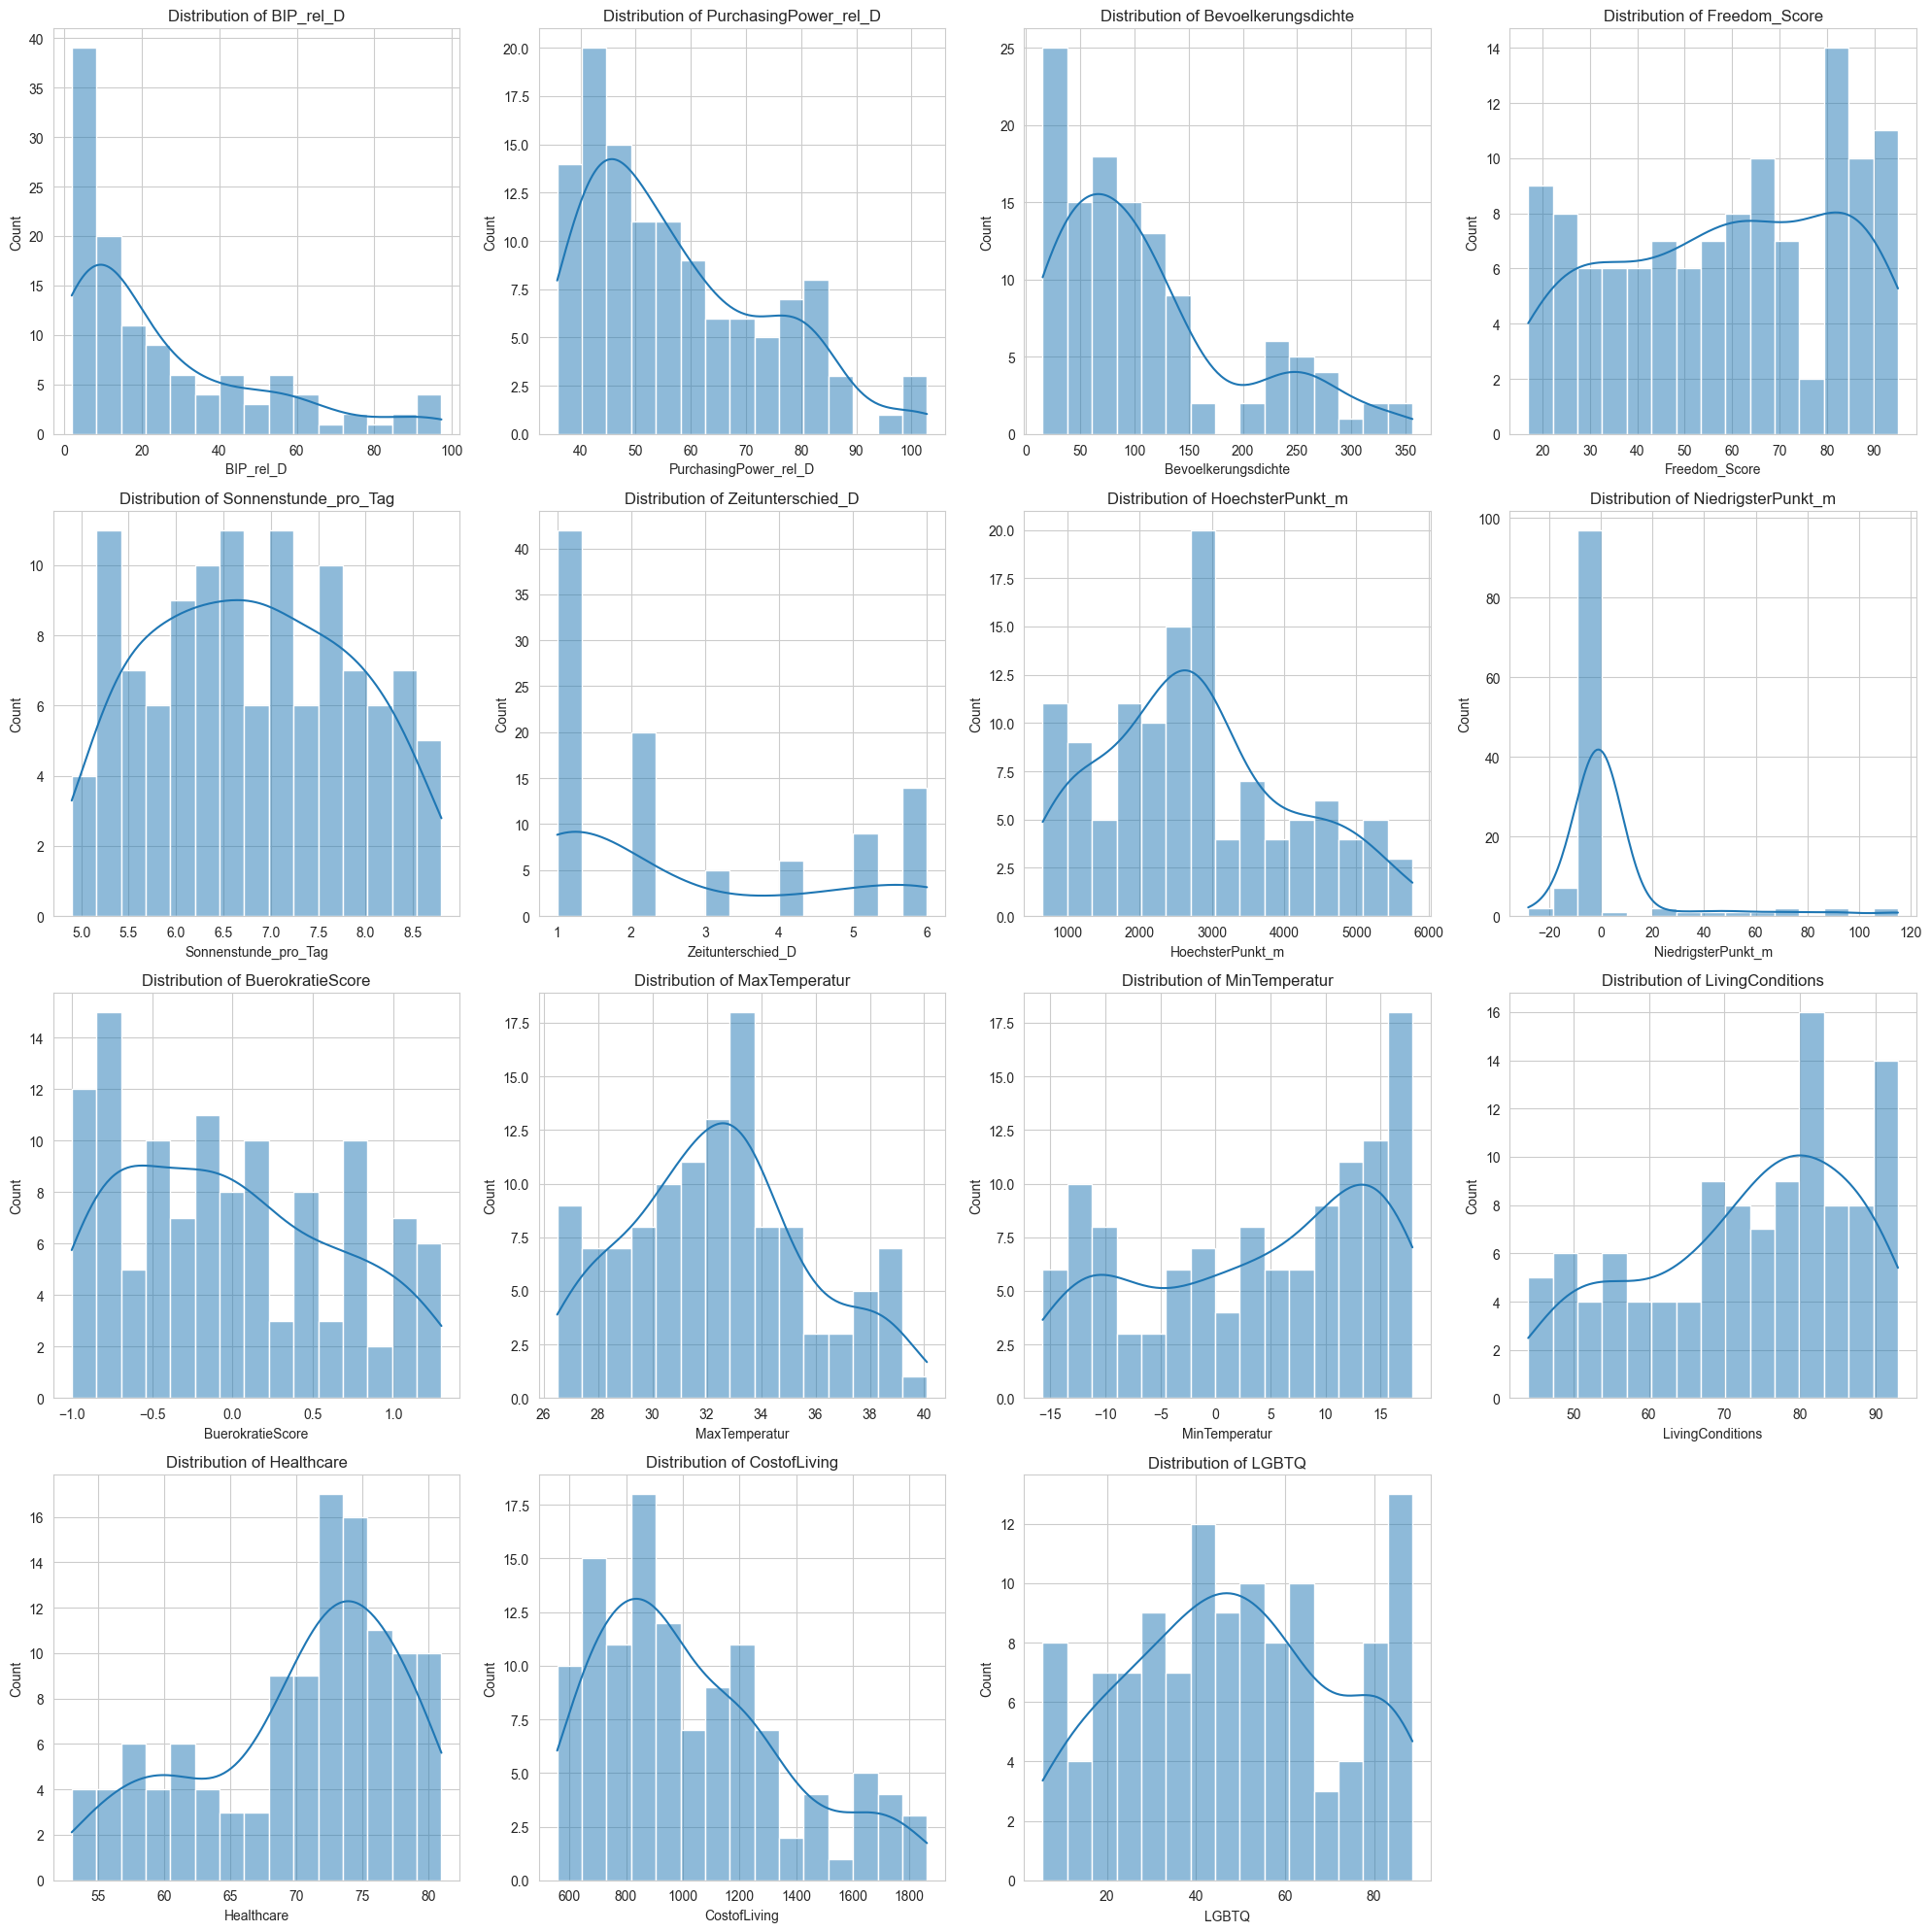

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set style
sns.set_style("whitegrid")

# Get numeric columns
numeric_cols = safe_countries_enough_data_red.select_dtypes(include=[np.number]).columns

# Create subplots
n_cols = 4
n_rows = len(numeric_cols) // n_cols + (1 if len(numeric_cols) % n_cols > 0 else 0)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 5*n_rows))
axes = axes.flatten() if n_rows > 1 else [axes] if n_cols == 1 else axes
edges_dict={}
for i, col in enumerate(numeric_cols):
    df_to_plot=skew_trimmer(col)[0]
    sns.histplot(data=df_to_plot, x=col, ax=axes[i], kde=1, bins=15)
    axes[i].set_title(f'Distribution of {col}')
    # Create histogram and capture the bin information
    data = df_to_plot[col].dropna()

# Create histogram and capture the bin information
    if col == "Zeitunterschied_D":
        counts, bin_edges, patches = plt.hist(data, bins=5)
    else:
        counts, bin_edges, patches = plt.hist(data, bins=15)
    if col in int_cols:
        bin_edges = bin_edges.round(0).astype(int)
    else:
        bin_edges = bin_edges.round(1)
    edges_dict[col]=bin_edges
    print(f"Bin edges: {bin_edges}")
    print(f"Bin counts: {counts}")
    print(f"Number of bins: {len(bin_edges) - 1}")



# Hide unused subplots
for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

In [105]:
exceptions_for_sliders=[
 'Freedom_Score',
 'BuerokratieScore',
 'LivingConditions',
 'Healthcare',
 'LGBTQ']

In [130]:

boundaries_dict={}
for col in safe_countries_enough_data_red.columns[3:]:
    if "boolean" in col:
        boundaries_dict[col]={}
    
    else:
        if col in int_cols:
            results_list=skew_trimmer(col)
            span=results_list[1]-results_list[2]
            
            if col in exceptions_for_sliders:
                lower_slider=edges_dict[col][round(len(edges_dict[col])/2)]
                upper_slider=None
                boundaries_dict[col]={
                                "selectedMin":int(lower_slider),
                                "selectedMax":(upper_slider),
                                "upper":int(results_list[1]),
                                "lower":int(results_list[2])}
            else:
                lower_slider=edges_dict[col][2]
                upper_slider=edges_dict[col][-3]
                boundaries_dict[col]={
                                    "selectedMin":int(lower_slider),
                                    "selectedMax":int(upper_slider),
                                    "upper":int(results_list[1]),
                                    "lower":int(results_list[2])}
        else:
            results_list=skew_trimmer(col)
            span=results_list[1]-results_list[2]
            if col in exceptions_for_sliders:
                lower_slider=edges_dict[col][round(len(edges_dict[col])/2)]
                upper_slider=None
                boundaries_dict[col]={
                                "selectedMin":float(lower_slider),
                                "selectedMax":(upper_slider),
                                "upper":float(results_list[1]),
                                "lower":float(results_list[2])}
            else:
                lower_slider=edges_dict[col][2]
                upper_slider=edges_dict[col][-3]
                boundaries_dict[col]={"selectedMin":float(lower_slider),
                                "selectedMax":float(upper_slider),
                                "upper":float(results_list[1]),
                                "lower":float(results_list[2])}

In [131]:
# First install the library if you haven't: pip install pycountry-convert
import pycountry_convert as pc

def get_continent_from_iso3(iso3_code):
    """
    Convert ISO-3 country code to continent name
    """
    try:
        # Convert ISO3 to ISO2
        iso2_code = pc.country_alpha3_to_country_alpha2(iso3_code)
        # Get continent code
        continent_code = pc.country_alpha2_to_continent_code(iso2_code)
        # Convert continent code to continent name
        continent_name = pc.convert_continent_code_to_continent_name(continent_code)
        return continent_name
    except:
        return "Unknown"

# Test with some examples
test_codes = ['USA', 'GBR', 'DEU', 'JPN', 'BRA', 'EGY', 'AUS']
for code in test_codes:
    continent = get_continent_from_iso3(code)
    print(f"{code}: {continent}")

USA: North America
GBR: Europe
DEU: Europe
JPN: Asia
BRA: South America
EGY: Africa
AUS: Oceania


In [132]:
english_to_german_continents = {
    'Europe': 'Europa',
    'North America': 'Nordamerika', 
    'South America': 'Südamerika',
    'Asia': 'Asien',
    'Africa': 'Afrika',
    'Oceania': 'Ozeanien',
    'Antarctica': 'Antarktis',
    'Unknown': 'Unbekannt'
}

In [133]:
country_info_json=[]
for isocode in countries_dict.keys():
    print(isocode)
    continent=get_continent_from_iso3(isocode)
    land=df_to_check[df_to_check["Country Code"]==isocode]["Land"].values[0]
    country_name=df_to_check[df_to_check["Country Code"]==isocode]["Country Name"].values[0]
    german_continent_name=english_to_german_continents[continent]
    country_entry={"id":isocode,"label":land,"country":country_name,"groupID":german_continent_name,"output":countries_dict[isocode]}
    country_info_json.append(country_entry)
country_info_json


ALB
DZA
AGO
ARG
ARM
AUS
AUT
AZE
BHR
BGD
BEL
BLZ
BEN
BOL
BIH
BWA
BRA
BGR
BFA
BDI
CPV
KHM
CMR
CAN
TCD
CHL
CHN
COL
COM
COD
COG
CRI
CIV
HRV
CYP
CZE
DNK
DJI
DOM
ECU
EGY
SLV
GNQ
ERI
EST
SWZ
ETH
FIN
FRA
GAB
GMB
GEO
DEU
GHA
GRC
GTM
GIN
GNB
GUY
HND
HUN
ISL
IND
IDN
IRQ
IRL
ISR
ITA
JAM
JPN
JOR
KAZ
KEN
KOR
KWT
KGZ
LAO
LVA
LBN
LSO
LBR
LTU
LUX
MDG
MWI
MYS
MLT
MRT
MUS
MEX
MDA
MNG
MNE
MAR
MOZ
NAM
NPL
NLD
NZL
NIC
NGA
MKD
NOR
OMN
PAK
PAN
PNG
PRY
PER
PHL
POL
PRT
QAT
ROU
RUS
RWA
STP
SAU
SEN
SRB
SYC
SLE
SGP
SVK
SVN
ZAF
ESP
LKA
SUR
SWE
CHE
TJK
TZA
THA
TGO
TTO
TUN
TUR
TKM
UGA
ARE
GBR
USA
URY
UZB
VEN
VNM
ZMB
ZWE


[{'id': 'ALB',
  'label': 'Albanien',
  'country': 'Albania',
  'groupID': 'Europa',
  'output': [{'id': 'BIP_rel_D', 'displayValue': 17.9, 'binValue': 17.9},
   {'id': 'PurchasingPower_rel_D', 'displayValue': 55.2, 'binValue': 55.2},
   {'id': 'Bevoelkerungsdichte', 'displayValue': 100.2, 'binValue': 100.2},
   {'id': 'Freedom_Score', 'displayValue': 68, 'binValue': 68},
   {'id': 'Sonnenstunde_pro_Tag', 'displayValue': 7.0, 'binValue': 7.0},
   {'id': 'Zeitunterschied_D', 'displayValue': 0, 'binValue': 0},
   {'id': 'HoechsterPunkt_m', 'displayValue': 2764, 'binValue': 2764},
   {'id': 'NiedrigsterPunkt_m', 'displayValue': 0, 'binValue': 0},
   {'id': 'BuerokratieScore', 'displayValue': 0.3, 'binValue': 0.3},
   {'id': 'MaxTemperatur', 'displayValue': 31.2, 'binValue': 31.2},
   {'id': 'MinTemperatur', 'displayValue': -6.2, 'binValue': -6.2},
   {'id': 'LivingConditions', 'displayValue': 72, 'binValue': 72},
   {'id': 'Healthcare', 'displayValue': 73, 'binValue': 73},
   {'id': 'Cost

In [134]:
country_info_json

[{'id': 'ALB',
  'label': 'Albanien',
  'country': 'Albania',
  'groupID': 'Europa',
  'output': [{'id': 'BIP_rel_D', 'displayValue': 17.9, 'binValue': 17.9},
   {'id': 'PurchasingPower_rel_D', 'displayValue': 55.2, 'binValue': 55.2},
   {'id': 'Bevoelkerungsdichte', 'displayValue': 100.2, 'binValue': 100.2},
   {'id': 'Freedom_Score', 'displayValue': 68, 'binValue': 68},
   {'id': 'Sonnenstunde_pro_Tag', 'displayValue': 7.0, 'binValue': 7.0},
   {'id': 'Zeitunterschied_D', 'displayValue': 0, 'binValue': 0},
   {'id': 'HoechsterPunkt_m', 'displayValue': 2764, 'binValue': 2764},
   {'id': 'NiedrigsterPunkt_m', 'displayValue': 0, 'binValue': 0},
   {'id': 'BuerokratieScore', 'displayValue': 0.3, 'binValue': 0.3},
   {'id': 'MaxTemperatur', 'displayValue': 31.2, 'binValue': 31.2},
   {'id': 'MinTemperatur', 'displayValue': -6.2, 'binValue': -6.2},
   {'id': 'LivingConditions', 'displayValue': 72, 'binValue': 72},
   {'id': 'Healthcare', 'displayValue': 73, 'binValue': 73},
   {'id': 'Cost

In [135]:
def german_sort_key(text):
    """Convert German umlauts for proper sorting"""
    replacements = {
        'ä': 'a', 'Ä': 'A',
        'ö': 'o', 'Ö': 'O', 
        'ü': 'u', 'Ü': 'U',
        'ß': 'ss'
    }
    for umlaut, replacement in replacements.items():
        text = text.replace(umlaut, replacement)
    return text.lower()

# Sort with custom key
country_info_json_sorted = sorted(country_info_json, key=lambda x: german_sort_key(x['label']))
country_info_json_sorted

[{'id': 'EGY',
  'label': 'Ägypten',
  'country': 'Egypt, Arab Rep.',
  'groupID': 'Afrika',
  'output': [{'id': 'BIP_rel_D', 'displayValue': 6.0, 'binValue': 6.0},
   {'id': 'PurchasingPower_rel_D', 'displayValue': 22.7, 'binValue': 35.7},
   {'id': 'Bevoelkerungsdichte', 'displayValue': 115.1, 'binValue': 115.1},
   {'id': 'Freedom_Score', 'displayValue': 18, 'binValue': 18},
   {'id': 'Sonnenstunde_pro_Tag', 'displayValue': 10.2, 'binValue': 8.9},
   {'id': 'Zeitunterschied_D', 'displayValue': 0, 'binValue': 0},
   {'id': 'HoechsterPunkt_m', 'displayValue': 2629, 'binValue': 2629},
   {'id': 'NiedrigsterPunkt_m', 'displayValue': -133, 'binValue': -29},
   {'id': 'BuerokratieScore', 'displayValue': -0.2, 'binValue': -0.2},
   {'id': 'MaxTemperatur', 'displayValue': 40.1, 'binValue': 40.1},
   {'id': 'MinTemperatur', 'displayValue': 3.9, 'binValue': 3.9},
   {'id': 'LivingConditions', 'displayValue': 73, 'binValue': 73},
   {'id': 'Healthcare', 'displayValue': 66, 'binValue': 66},
   

In [136]:
import json

# Write with nice formatting
with open('country_info_formatted_jan.json', 'w', encoding='utf-8') as f:
    json.dump(country_info_json_sorted, f, 
              indent=4,           # 4-space indentation
              ensure_ascii=False, # Keep unicode characters (like ä, ü, ö)
              sort_keys=1)     # Sort keys alphabetically

print("Formatted JSON file saved!")

Formatted JSON file saved!


In [137]:
country_info_json_sorted

[{'id': 'EGY',
  'label': 'Ägypten',
  'country': 'Egypt, Arab Rep.',
  'groupID': 'Afrika',
  'output': [{'id': 'BIP_rel_D', 'displayValue': 6.0, 'binValue': 6.0},
   {'id': 'PurchasingPower_rel_D', 'displayValue': 22.7, 'binValue': 35.7},
   {'id': 'Bevoelkerungsdichte', 'displayValue': 115.1, 'binValue': 115.1},
   {'id': 'Freedom_Score', 'displayValue': 18, 'binValue': 18},
   {'id': 'Sonnenstunde_pro_Tag', 'displayValue': 10.2, 'binValue': 8.9},
   {'id': 'Zeitunterschied_D', 'displayValue': 0, 'binValue': 0},
   {'id': 'HoechsterPunkt_m', 'displayValue': 2629, 'binValue': 2629},
   {'id': 'NiedrigsterPunkt_m', 'displayValue': -133, 'binValue': -29},
   {'id': 'BuerokratieScore', 'displayValue': -0.2, 'binValue': -0.2},
   {'id': 'MaxTemperatur', 'displayValue': 40.1, 'binValue': 40.1},
   {'id': 'MinTemperatur', 'displayValue': 3.9, 'binValue': 3.9},
   {'id': 'LivingConditions', 'displayValue': 73, 'binValue': 73},
   {'id': 'Healthcare', 'displayValue': 66, 'binValue': 66},
   

In [138]:
safe_countries_enough_data_red.columns

Index(['Country Name', 'Country Code', 'Land', 'BIP_rel_D',
       'PurchasingPower_rel_D', 'Bevoelkerungsdichte', 'Freedom_Score',
       'Sonnenstunde_pro_Tag', 'Zeitunterschied_D', 'HoechsterPunkt_m',
       'NiedrigsterPunkt_m', 'BuerokratieScore', 'MaxTemperatur',
       'MinTemperatur', 'LivingConditions', 'Healthcare', 'CostofLiving',
       'LGBTQ', 'Mehrals5Morde_pro_100k_boolean',
       'Mehrals1000Deutsche_boolean', 'Alkoholverbot_boolean',
       'Kueste_boolean', 'Christian_boolean', 'Muslim_boolean',
       'Jewish_boolean', 'English_boolean', 'Cuisine_boolean'],
      dtype='object')

In [139]:
# Fixed version - use lists as VALUES, not wrapped in sets
classifier_dict = {
    "Beliebte Kriterien": [
                'Kueste_boolean', 'Sonnenstunde_pro_Tag', 'CostofLiving', 'Mehrals1000Deutsche_boolean', 
        'English_boolean','Cuisine_boolean',
    ],
    "Geografie/Klima": [
        'Sonnenstunde_pro_Tag', 'Kueste_boolean', 'HoechsterPunkt_m', 
        'NiedrigsterPunkt_m', 'MaxTemperatur', 'MinTemperatur', 'Zeitunterschied_D'
    ],
    
    "Wirtschaft/Gesundheit": [
        'BIP_rel_D', 'PurchasingPower_rel_D', 
        'CostofLiving', 'LivingConditions', 'Healthcare'
    ],
    
    "Freiheit/Sicherheit": [
        'Mehrals5Morde_pro_100k_boolean', 'Freedom_Score', 'BuerokratieScore', 'LGBTQ', 'Alkoholverbot_boolean'
    ],
    
    "Menschen/Religion": [
        'Bevoelkerungsdichte', 'Cuisine_boolean', 
        'English_boolean', 'Mehrals1000Deutsche_boolean','Christian_boolean', 'Muslim_boolean',
        'Jewish_boolean'
    ]
}

print(classifier_dict)

{'Beliebte Kriterien': ['Kueste_boolean', 'Sonnenstunde_pro_Tag', 'CostofLiving', 'Mehrals1000Deutsche_boolean', 'English_boolean', 'Cuisine_boolean'], 'Geografie/Klima': ['Sonnenstunde_pro_Tag', 'Kueste_boolean', 'HoechsterPunkt_m', 'NiedrigsterPunkt_m', 'MaxTemperatur', 'MinTemperatur', 'Zeitunterschied_D'], 'Wirtschaft/Gesundheit': ['BIP_rel_D', 'PurchasingPower_rel_D', 'CostofLiving', 'LivingConditions', 'Healthcare'], 'Freiheit/Sicherheit': ['Mehrals5Morde_pro_100k_boolean', 'Freedom_Score', 'BuerokratieScore', 'LGBTQ', 'Alkoholverbot_boolean'], 'Menschen/Religion': ['Bevoelkerungsdichte', 'Cuisine_boolean', 'English_boolean', 'Mehrals1000Deutsche_boolean', 'Christian_boolean', 'Muslim_boolean', 'Jewish_boolean']}


In [140]:
# Create a reverse mapping: column -> category
column_to_category = {}
for category, columns in classifier_dict.items():
    for column in columns:
        column_to_category[column] = category

print("Column to Category mapping:")
print(column_to_category)

Column to Category mapping:
{'Kueste_boolean': 'Geografie/Klima', 'Sonnenstunde_pro_Tag': 'Geografie/Klima', 'CostofLiving': 'Wirtschaft/Gesundheit', 'Mehrals1000Deutsche_boolean': 'Menschen/Religion', 'English_boolean': 'Menschen/Religion', 'Cuisine_boolean': 'Menschen/Religion', 'HoechsterPunkt_m': 'Geografie/Klima', 'NiedrigsterPunkt_m': 'Geografie/Klima', 'MaxTemperatur': 'Geografie/Klima', 'MinTemperatur': 'Geografie/Klima', 'Zeitunterschied_D': 'Geografie/Klima', 'BIP_rel_D': 'Wirtschaft/Gesundheit', 'PurchasingPower_rel_D': 'Wirtschaft/Gesundheit', 'LivingConditions': 'Wirtschaft/Gesundheit', 'Healthcare': 'Wirtschaft/Gesundheit', 'Mehrals5Morde_pro_100k_boolean': 'Freiheit/Sicherheit', 'Freedom_Score': 'Freiheit/Sicherheit', 'BuerokratieScore': 'Freiheit/Sicherheit', 'LGBTQ': 'Freiheit/Sicherheit', 'Alkoholverbot_boolean': 'Freiheit/Sicherheit', 'Bevoelkerungsdichte': 'Menschen/Religion', 'Christian_boolean': 'Menschen/Religion', 'Muslim_boolean': 'Menschen/Religion', 'Jewish_b

In [141]:
id_title={'Sonnenstunde_pro_Tag': 'Sonnenstunden pro Tag',
  'Kueste_boolean': 'Meeresküste', 
  'HoechsterPunkt_m': 'Höchster Berg', 
  'NiedrigsterPunkt_m': "Niedrigstes Tal des Landes", 
  'MaxTemperatur': 'Maximale Monatstemperatur', 
  'MinTemperatur': 'Minimale Monatstemperatur', 
  'Zeitunterschied_D': 'Zeitverschiebung zu Deutschland', 
  'BIP_rel_D': 'Bruttoinlandsprodukt im Vergleich zu Deutschland', 
  'PurchasingPower_rel_D': 'Kaufkraft im Vergleich zu Deutschland', 
  'CostofLiving': 'Lebenshaltungskosten im Land', 
  'LivingConditions': 'Lebensqualität im Land', 
  'Healthcare': 'Qualität des Gesundheitssystems', 
  'Christian_boolean': 'Christliche Bevölkerung', 
  'Muslim_boolean': 'Muslimische Bevölkerung', 
  'Jewish_boolean': 'Jüdische Bevölkerung', 
  'Mehrals5Morde_pro_100k_boolean': 'Viel tödliche Kriminalität', 
  'Freedom_Score': 'Bürgerliche Freiheiten', 
  'BuerokratieScore': 'Ordnung und Recht', 
  'LGBTQ': 'Gleichstellung der LGBTQ-Community', 
  'Alkoholverbot_boolean': 'Striktes Alkoholverbot', 
  'Bevoelkerungsdichte': 'Bevölkerungsdichte', 
  'Cuisine_boolean': 'Ausgezeichnete Landesküche', 
  'English_boolean': 'Englisch der Einheimischen', 
  'Mehrals1000Deutsche_boolean': 'Deutsche Community im Land'}


In [142]:
id_einheit={'Sonnenstunde_pro_Tag': 'Std/Tag',
            'Kueste_boolean': 'Nein/Ja',
  'HoechsterPunkt_m': 'm', 
  'NiedrigsterPunkt_m': 'm', 
  'MaxTemperatur': '°C', 
  'MinTemperatur': '°C', 
  'Zeitunterschied_D': 'Std', 
  'BIP_rel_D': '%', 
  'PurchasingPower_rel_D': '%', 
  'CostofLiving': '$', 
  'LivingConditions': 'Indexpunkte', 
  'Healthcare': 'Indexpunkte', 
  'Freedom_Score': 'Indexpunkte', 
  'BuerokratieScore': 'Indexpunkte', 
  'LGBTQ': 'Indexpunkte', 
  'Bevoelkerungsdichte': 'Ew./km2', 
  'Cuisine_boolean': 'Nein/Ja', 
  'English_boolean': 'Nein/Ja',
  'Anzahl_der_Deutschen_numeric': 'Ew.',
  'Christian_boolean': 'Nein/Ja', 
  'Muslim_boolean': 'Nein/Ja', 
  'Jewish_boolean': 'Nein/Ja', 
  'Mehrals5Morde_pro_100k_boolean': 'Nein/Ja', 
    'Alkoholverbot_boolean': 'Nein/Ja', 
    "Mehrals1000Deutsche_boolean": 'Nein/Ja'}

In [143]:
id_descript={'Sonnenstunde_pro_Tag': 'Wie viel Sonnenstunden pro Tag sollte es geben?',
            'Kueste_boolean': 'Wollen Sie, dass Ihr Wunschland eine Meeresküste hat?',
  'HoechsterPunkt_m': 'Wie hoch soll der höchste Punkt des Landes liegen?', 
  'NiedrigsterPunkt_m': 'Wie tief soll der niedrigste Punkt des Landes liegen?', 
  'MaxTemperatur': 'Wie heiß darf es maximal werden in Ihrem Wunschland? (mittlere Monatstemperatur)', 
  'MinTemperatur': 'Wie kalt darf es minimal werden in Ihrem Wunschland? (mittlere Monatstemperatur)', 
  'Zeitunterschied_D': 'In welchem Rahmen sollte sich der Zeitunterschied zu Deutschland befinden?', 
  'BIP_rel_D': 'Wie groß sollte die Wirtschaftsleistung pro Kopf im Vergleich zu Deutschland sein?', 
  'PurchasingPower_rel_D': 'Wo sollte die Kaufkraft liegen im Vergleich zu Deutschland?', 
  'CostofLiving': 'Wo sollten sich die Lebenshaltungskosten befinden (Miete, Lebensmittel, Transport)?', 
  'LivingConditions': 'Wie sollte es um die Lebensqualität bestellt sein? (basierend auf Daten zu Grundversorgung, Anbindung, Wohnraum gemäß Legatum Institut)',
  'Healthcare': 'Wie sollte es um die Gesundheitsversorgung bestellt sein? (basierend auf Daten zu Gesundheitssystem, Sterblichkeit, Risikofaktoren gemäß Legatum Institut)', 
  'Freedom_Score': 'Wo sollte das Niveau der bürgerlichen Freiheiten liegen? (basierend auf Daten zu Wahlen, Meinungsfreiheit, Rechtsstaatlichkeit gemäß Freedom House)', 
  'BuerokratieScore': 'Wo sollte das Maß an Ordnung und Bürokratie liegen? (Index von -5 bis +5 gemäß OECD)', 
  'LGBTQ': 'Wie sollte es um die LGBTQ-Rechte im Land stehen? (basierend auf Daten zu rechtlicher Gleichstellung und gesellschaftlicher Akzeptanz gemäß EqualDex Institut)', 
  'Bevoelkerungsdichte': 'Wie dicht soll das Land besiedelt sein? (Einwohner pro Quadratkilometer)', 
  'Cuisine_boolean': 'Gilt die Küche des Landes als besonders gut? (Top 100 gemäß Taste Atlas)', 
  'English_boolean': 'Kommt man mit Englisch gut zurecht? (Englisch ist Landessprache oder wird überdurchschnittlich gut gesprochen)',
  'Christian_boolean': 'Gibt es einen nennenswerten christlichen Bevölkerungsanteil? (mehr als ein Prozent)', 
  'Muslim_boolean': 'Gibt es einen nennenswerten muslimischen Bevölkerungsanteil? (mehr als ein Prozent)', 
  'Jewish_boolean': 'Gibt es einen nennenswerten jüdischen Bevölkerungsanteil? (mehr als ein Prozent)', 
  'Mehrals5Morde_pro_100k_boolean': 'Gibt es viele Gewaltverbrechen? (mehr als 5 Morde pro 100.000 Einwohner)', 
    'Alkoholverbot_boolean': 'Herrscht ein striktes Alkoholverbot im Land?', 
    "Mehrals1000Deutsche_boolean": 'Gibt es eine nennenswerte deutsche Expat-Community? (mehr als 1000 Deutsche im Land)'}

In [144]:
boundaries_dict

{'BIP_rel_D': {'selectedMin': 14.6,
  'selectedMax': 84.6,
  'upper': 97.8,
  'lower': 1.8},
 'PurchasingPower_rel_D': {'selectedMin': 44.7,
  'selectedMax': 93.9,
  'upper': 103.2,
  'lower': 35.7},
 'Bevoelkerungsdichte': {'selectedMin': 61.1,
  'selectedMax': 310.8,
  'upper': 362.0,
  'lower': 15.6},
 'Freedom_Score': {'selectedMin': 59,
  'selectedMax': None,
  'upper': 96,
  'lower': 15},
 'Sonnenstunde_pro_Tag': {'selectedMin': 5.4,
  'selectedMax': 8.3,
  'upper': 8.9,
  'lower': 4.8},
 'Zeitunterschied_D': {'selectedMin': 3,
  'selectedMax': 4,
  'upper': 7,
  'lower': 0},
 'HoechsterPunkt_m': {'selectedMin': 1340,
  'selectedMax': 5093,
  'upper': 5799,
  'lower': 654},
 'NiedrigsterPunkt_m': {'selectedMin': -9,
  'selectedMax': 96,
  'upper': 118,
  'lower': -29},
 'BuerokratieScore': {'selectedMin': 0.2,
  'selectedMax': None,
  'upper': 1.4,
  'lower': -1.1},
 'MaxTemperatur': {'selectedMin': 28.3,
  'selectedMax': 38.3,
  'upper': 40.3,
  'lower': 26.4},
 'MinTemperatur':

In [145]:
colour_category_dict={
    "Beliebte Kriterien": "purple",
    "Geografie/Klima": "yellow",
    "Wirtschaft/Gesundheit": "green",  
    "Freiheit/Sicherheit": "blue",  
    "Menschen/Religion": "orange"}

In [146]:
boolean_titles_subtitles = {
    "Kueste_boolean": {
        "booleanTexts": {
            "true": {
                "title": "Mit Meeresküste",
                "description": "Das Land hat eine Meeresküste.",
            },
            "false": {
                "title": "Keine Meeresküste",
                "description": "Das Land hat keine Meeresküste.",
            },
        },
        "defaultValue": True,
    },
    "Cuisine_boolean": {
        "booleanTexts": {
            "true": {
                "title": "Gute Landesküche",
                "description": "Die Landesküche gehört zu den Top 100 weltweit.",
            },
            "false": {
                "title": "Keine gute Landesküche",
                "description": "Die Landesküche gehört nicht zu den Top 100 weltweit.",
            },
        },
        "defaultValue": True,
    },
    "English_boolean": {
        "booleanTexts": {
            "true": {
                "title": "Solides Englisch",
                "description": "Sie sollten mit Englisch gut durch den Alltag kommen.",
            },
            "false": {
                "title": "Kein solides Englisch",
                "description": "Sie könnten mit Englisch Probleme im Alltag haben.",
            },
        },
        "defaultValue": True,
    },
    "Christian_boolean": {
        "booleanTexts": {
            "true": {
                "title": "Nennenswerte christliche Bevölkerung",
                "description": "Es gibt eine größere christliche Bevölkerungsgruppe im Land.",
            },
            "false": {
                "title": "Keine nennenswerte christliche Bevölkerung",
                "description": "Es gibt keine größere christliche Bevölkerungsgruppe im Land.",
            },
        },
        "defaultValue": True,
    },
    "Muslim_boolean": {
        "booleanTexts": {
            "true": {
                "title": "Nennenswerte muslimische Bevölkerung",
                "description": "Es gibt eine größere muslimische Bevölkerungsgruppe im Land.",
            },
            "false": {
                "title": "Keine nennenswerte muslimische Bevölkerung",
                "description": "Es gibt keine größere muslimische Bevölkerungsgruppe im Land.",
            },
        },
        "defaultValue": True,
    },
    "Jewish_boolean": {
        "booleanTexts": {
            "true": {
                "title": "Nennenswerte jüdische Bevölkerung",
                "description": "Es gibt eine größere jüdische Bevölkerungsgruppe im Land.",
            },
            "false": {
                "title": "Keine nennenswerte jüdische Bevölkerung",
                "description": "Es gibt keine größere jüdische Bevölkerungsgruppe im Land.",
            },
        },
        "defaultValue": True,
    },
    "Mehrals5Morde_pro_100k_boolean": {
        "booleanTexts": {
            "true": {
                "title": "Viel brutale Kriminalität",
                "description": "Es gibt mehr als fünf Morde pro 100.000 Einwohner im Land.",
            },
            "false": {
                "title": "Weniger brutale Kriminalität",
                "description": "Es gibt weniger als fünf Morde pro 100.000 Einwohner im Land.",
            },
        },
        "defaultValue": False,
    },
    "Alkoholverbot_boolean": {
        "booleanTexts": {
            "true": {
                "title": "Striktes Alkoholverbot",
                "description": "Im Land gibt es ein striktes Alkoholverbot.",
            },
            "false": {
                "title": "Kein striktes Alkoholverbot",
                "description": "Im Land gibt es kein striktes Alkoholverbot.",
            },
        },
        "defaultValue": False,
    },
    "Mehrals1000Deutsche_boolean": {
        "booleanTexts": {
            "true": {
                "title": "Nennenswerte deutsche Community",
                "description": "Es gibt eine größere deutsche Community im Land.",
            },
            "false": {
                "title": "Keine nennenswerte deutsche Community",
                "description": "Es gibt keine größere deutsche Community im Land.",
            },
            "defaultValue": True,
        }
    },
}

In [147]:
item_to_category = {}
for category, items in classifier_dict.items():
    for item in items:
        if (category)!="Beliebte Kriterien":
            item_to_category[item] = category

print(item_to_category)
# {'Mehrals1000Deutsche_boolean': 'Beliebte Kriterien', 
#  'Kueste_boolean': 'Beliebte Kriterien', ...}

{'Sonnenstunde_pro_Tag': 'Geografie/Klima', 'Kueste_boolean': 'Geografie/Klima', 'HoechsterPunkt_m': 'Geografie/Klima', 'NiedrigsterPunkt_m': 'Geografie/Klima', 'MaxTemperatur': 'Geografie/Klima', 'MinTemperatur': 'Geografie/Klima', 'Zeitunterschied_D': 'Geografie/Klima', 'BIP_rel_D': 'Wirtschaft/Gesundheit', 'PurchasingPower_rel_D': 'Wirtschaft/Gesundheit', 'CostofLiving': 'Wirtschaft/Gesundheit', 'LivingConditions': 'Wirtschaft/Gesundheit', 'Healthcare': 'Wirtschaft/Gesundheit', 'Mehrals5Morde_pro_100k_boolean': 'Freiheit/Sicherheit', 'Freedom_Score': 'Freiheit/Sicherheit', 'BuerokratieScore': 'Freiheit/Sicherheit', 'LGBTQ': 'Freiheit/Sicherheit', 'Alkoholverbot_boolean': 'Freiheit/Sicherheit', 'Bevoelkerungsdichte': 'Menschen/Religion', 'Cuisine_boolean': 'Menschen/Religion', 'English_boolean': 'Menschen/Religion', 'Mehrals1000Deutsche_boolean': 'Menschen/Religion', 'Christian_boolean': 'Menschen/Religion', 'Muslim_boolean': 'Menschen/Religion', 'Jewish_boolean': 'Menschen/Religion'

In [148]:
edges_dict["LGBTQ"][-1]

np.float64(88.6)

In [149]:
input_json=[]
for category in classifier_dict.keys():
    print(category)
    print(classifier_dict[category])
    items_json=[]
    for item in classifier_dict[category]:
        #print(item)
        #print(category)
        category_filtered=item_to_category[item]
        
        if "_boolean" in item:
            filtertype="boolean"
            category_input={
            "type": filtertype,
            "id": item,
            "title": id_title[item],
            "description": id_descript[item],
            "color": colour_category_dict[category_filtered],
            "config": boolean_titles_subtitles[item]
           
            }
        else:
            filtertype="slider"
            category_input={
            "type": filtertype,
            "id": item,
            "title": id_title[item],
            "description": id_descript[item],

            "color": colour_category_dict[category_filtered],
            "config": {
            "min":boundaries_dict[item]["lower"],
            "max": boundaries_dict[item]["upper"],
            "selectedMin":boundaries_dict[item]["selectedMin"],
            "selectedMax": boundaries_dict[item]["selectedMax"],

            "threshold": edges_dict[item].tolist(),
            "unit": id_einheit[item]
            }
  
    }
        items_json.append(category_input)
    input_json.append({
        "title": category,
        "color": colour_category_dict[category],
        "items": items_json
    })
input_json
        

Beliebte Kriterien
['Kueste_boolean', 'Sonnenstunde_pro_Tag', 'CostofLiving', 'Mehrals1000Deutsche_boolean', 'English_boolean', 'Cuisine_boolean']
Geografie/Klima
['Sonnenstunde_pro_Tag', 'Kueste_boolean', 'HoechsterPunkt_m', 'NiedrigsterPunkt_m', 'MaxTemperatur', 'MinTemperatur', 'Zeitunterschied_D']
Wirtschaft/Gesundheit
['BIP_rel_D', 'PurchasingPower_rel_D', 'CostofLiving', 'LivingConditions', 'Healthcare']
Freiheit/Sicherheit
['Mehrals5Morde_pro_100k_boolean', 'Freedom_Score', 'BuerokratieScore', 'LGBTQ', 'Alkoholverbot_boolean']
Menschen/Religion
['Bevoelkerungsdichte', 'Cuisine_boolean', 'English_boolean', 'Mehrals1000Deutsche_boolean', 'Christian_boolean', 'Muslim_boolean', 'Jewish_boolean']


[{'title': 'Beliebte Kriterien',
  'color': 'purple',
  'items': [{'type': 'boolean',
    'id': 'Kueste_boolean',
    'title': 'Meeresküste',
    'description': 'Wollen Sie, dass Ihr Wunschland eine Meeresküste hat?',
    'color': 'yellow',
    'config': {'booleanTexts': {'true': {'title': 'Mit Meeresküste',
       'description': 'Das Land hat eine Meeresküste.'},
      'false': {'title': 'Keine Meeresküste',
       'description': 'Das Land hat keine Meeresküste.'}},
     'defaultValue': True}},
   {'type': 'slider',
    'id': 'Sonnenstunde_pro_Tag',
    'title': 'Sonnenstunden pro Tag',
    'description': 'Wie viel Sonnenstunden pro Tag sollte es geben?',
    'color': 'yellow',
    'config': {'min': 4.8,
     'max': 8.9,
     'selectedMin': 5.4,
     'selectedMax': 8.3,
     'threshold': [4.9,
      5.2,
      5.4,
      5.7,
      5.9,
      6.2,
      6.5,
      6.7,
      7.0,
      7.2,
      7.5,
      7.8,
      8.0,
      8.3,
      8.5,
      8.8],
     'unit': 'Std/Tag'}},
  

In [150]:
input_json

[{'title': 'Beliebte Kriterien',
  'color': 'purple',
  'items': [{'type': 'boolean',
    'id': 'Kueste_boolean',
    'title': 'Meeresküste',
    'description': 'Wollen Sie, dass Ihr Wunschland eine Meeresküste hat?',
    'color': 'yellow',
    'config': {'booleanTexts': {'true': {'title': 'Mit Meeresküste',
       'description': 'Das Land hat eine Meeresküste.'},
      'false': {'title': 'Keine Meeresküste',
       'description': 'Das Land hat keine Meeresküste.'}},
     'defaultValue': True}},
   {'type': 'slider',
    'id': 'Sonnenstunde_pro_Tag',
    'title': 'Sonnenstunden pro Tag',
    'description': 'Wie viel Sonnenstunden pro Tag sollte es geben?',
    'color': 'yellow',
    'config': {'min': 4.8,
     'max': 8.9,
     'selectedMin': 5.4,
     'selectedMax': 8.3,
     'threshold': [4.9,
      5.2,
      5.4,
      5.7,
      5.9,
      6.2,
      6.5,
      6.7,
      7.0,
      7.2,
      7.5,
      7.8,
      8.0,
      8.3,
      8.5,
      8.8],
     'unit': 'Std/Tag'}},
  

In [151]:

# Write with nice formatting
with open('input_formatted_feb.json', 'w', encoding='utf-8') as f:
    json.dump(input_json, f, 
              indent=4,           # 4-space indentation
              ensure_ascii=False, # Keep unicode characters (like ä, ü, ö)
              sort_keys=1)     # Sort keys alphabetically

print("Formatted JSON file saved!")

Formatted JSON file saved!


In [152]:
bin_edges

array([ 5.6, 11.1, 16.7, 22.2, 27.7, 33.3, 38.8, 44.3, 49.9, 55.4, 60.9,
       66.5, 72. , 77.5, 83.1, 88.6])

In [153]:
input_json

[{'title': 'Beliebte Kriterien',
  'color': 'purple',
  'items': [{'type': 'boolean',
    'id': 'Kueste_boolean',
    'title': 'Meeresküste',
    'description': 'Wollen Sie, dass Ihr Wunschland eine Meeresküste hat?',
    'color': 'yellow',
    'config': {'booleanTexts': {'true': {'title': 'Mit Meeresküste',
       'description': 'Das Land hat eine Meeresküste.'},
      'false': {'title': 'Keine Meeresküste',
       'description': 'Das Land hat keine Meeresküste.'}},
     'defaultValue': True}},
   {'type': 'slider',
    'id': 'Sonnenstunde_pro_Tag',
    'title': 'Sonnenstunden pro Tag',
    'description': 'Wie viel Sonnenstunden pro Tag sollte es geben?',
    'color': 'yellow',
    'config': {'min': 4.8,
     'max': 8.9,
     'selectedMin': 5.4,
     'selectedMax': 8.3,
     'threshold': [4.9,
      5.2,
      5.4,
      5.7,
      5.9,
      6.2,
      6.5,
      6.7,
      7.0,
      7.2,
      7.5,
      7.8,
      8.0,
      8.3,
      8.5,
      8.8],
     'unit': 'Std/Tag'}},
  